## Selfie_Related_Injuries

In [2]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [7]:
# import dataset
df=pd.read_csv('Selfie_Related_Injuries.csv')

In [8]:
df

,Date,Country,Injuries/Casualties,Type,Description
0,10/15/2011,United States,3,Transport,Three teenagers (two sisters and a friend) wer...
1,3/1/2014,Spain,1,Electrocution,A 21-year-old man was electrocuted after climb...
2,3/1/2014,Russia,1,Transport,Two people were walking near train tracks when...
3,4/1/2014,United States,1,Transport,A 32-year-old woman from North Carolina was dr...
4,4/22/2014,Russia,1,Fall,A 17-year-old girl fell 30 ft to her death aft...
...,...,...,...,...,...
187,5/16/2021,Indonesia,9,Drowned,A boat overloaded with 20 people in a reservoi...
188,7/10/2021,Hong Kong,1,Fall,32-year-old influencer Sofia Cheung died after...
189,7/11/2021,India,11,Electrocution,Eleven people died in the Indian state of Raja...
190,7/28/2021,Italy,1,Fall,A 22-year-old YouTuber from Denmark died after...


In [9]:
df.head(10)

,Date,Country,Injuries/Casualties,Type,Description
0,10/15/2011,United States,3,Transport,Three teenagers (two sisters and a friend) wer...
1,3/1/2014,Spain,1,Electrocution,A 21-year-old man was electrocuted after climb...
2,3/1/2014,Russia,1,Transport,Two people were walking near train tracks when...
3,4/1/2014,United States,1,Transport,A 32-year-old woman from North Carolina was dr...
4,4/22/2014,Russia,1,Fall,A 17-year-old girl fell 30 ft to her death aft...
5,5/1/2014,India,1,Transport,A 15-year-old boy was killed by a train while ...
6,5/31/2014,United States,2,Transport,A 29-year-old amateur pilot allegedly took sel...
7,6/1/2014,Italy,1,Fall,A 16-year-old girl died in Taranto after plung...
8,7/1/2014,Philippines,1,Fall,A 14-year-old high school student in the Phili...
9,7/24/2014,Belgium,1,Transport,A 12-year-old was with a second person taking ...


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Date                 192 non-null    object
 1   Country              192 non-null    object
 2   Injuries/Casualties  192 non-null    int64 
 3   Type                 192 non-null    object
 4   Description          192 non-null    object
dtypes: int64(1), object(4)
memory usage: 7.6+ KB


In [11]:
df['Date']=pd.to_datetime(df['Date'])

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.isnull().sum()

Date                   0
Country                0
Injuries/Casualties    0
Type                   0
Description            0
dtype: int64

In [14]:
df['Injuries/Casualties'].sort_values()

95      1
112     1
114     1
115     1
117     1
       ..
76      7
140     8
187     9
189    11
141    48
Name: Injuries/Casualties, Length: 192, dtype: int64

In [15]:
# drop outlier value
df.drop(141,inplace=True)

In [16]:
df['Injuries/Casualties'].sort_values()

95      1
112     1
114     1
115     1
117     1
       ..
22      7
76      7
140     8
187     9
189    11
Name: Injuries/Casualties, Length: 191, dtype: int64

In [17]:
df.describe()

,Date,Injuries/Casualties
count,191,191.000000
mean,2016-11-19 07:24:49.005235712,1.591623
min,2011-10-15 00:00:00,1.000000
25%,2015-11-01 00:00:00,1.000000
50%,2016-08-07 00:00:00,1.000000
75%,2017-07-26 00:00:00,2.000000
max,2021-08-06 00:00:00,11.000000
std,NaN,1.410761


In [19]:
# country with sum of injuries
x=df.groupby('Country')['Injuries/Casualties'].sum()

In [20]:
# most 5 countries have injuries
x.sort_values(ascending=False).head(5)

Country
India            139
United States     26
Russia            19
Pakistan          14
Indonesia         12
Name: Injuries/Casualties, dtype: int64

In [28]:
# Country with injuries type with sum of injuries
df.groupby(['Country','Type'])['Injuries/Casualties'].sum().sort_values(ascending=False)

Country    Type         
India      Drowned          65
           Fall             29
           Transport        24
           Electrocution    15
Indonesia  Drowned           9
                            ..
Kenya      Animal            1
Russia     Firearm           1
Ireland    Fall              1
Serbia     Transport         1
Pakistan   Fall              1
Name: Injuries/Casualties, Length: 77, dtype: int64

In [67]:
df.groupby('Country')['Injuries/Casualties'].count().sort_values()

Country
New Zealand          1
Uganda               1
South Africa         1
Slovenia             1
Serbia               1
Romania              1
Panama               1
Oman                 1
Nigeria              1
Malaysia             1
Kenya                1
Ireland              1
Vietnam              1
Hong Kong, China     1
Hong Kong            1
Greece               1
Chile                1
Belgium              1
Germany              2
Hungary              2
China                2
Thailand             2
Peru                 2
Turkey               2
Portugal             2
Mexico               3
Nepal                3
Colombia             3
Indonesia            4
United Kingdom       4
Italy                4
Croatia              4
Sri Lanka            4
Philippines          5
Brazil               5
Spain                5
Australia            5
Pakistan             8
Russia              14
United States       18
India               70
Name: Injuries/Casualties, dtype: int64

# Visualization

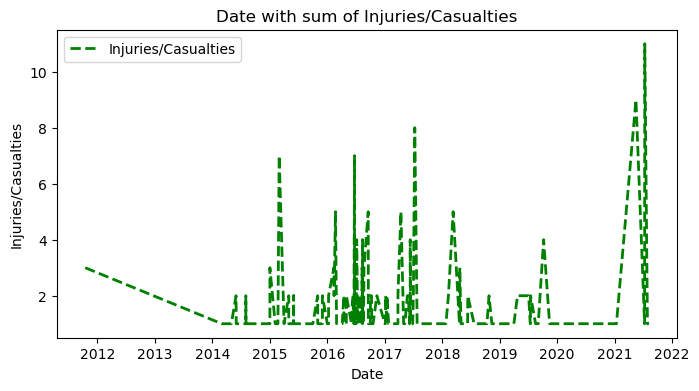

In [70]:
plt.figure(figsize=(8,4))
plt.plot(df['Date'],df['Injuries/Casualties'],ls='--',lw=2,c='green',label='Injuries/Casualties')
plt.xlabel('Date')
plt.ylabel('Injuries/Casualties')
plt.title('Date with sum of Injuries/Casualties')
plt.legend(loc=0)
plt.show()

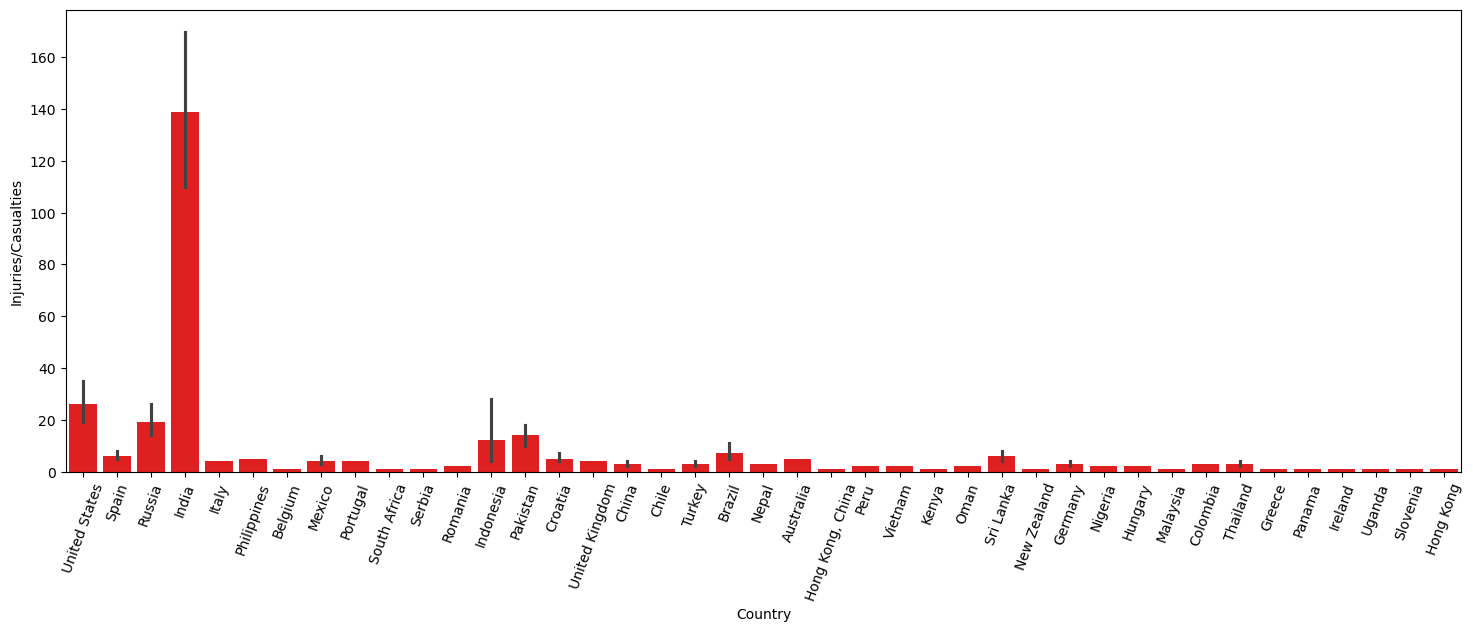

In [77]:
plt.figure(figsize=(18,6))
sns.barplot(data=df,x='Country',y='Injuries/Casualties',estimator='sum',color='red')
plt.xticks(rotation=70)
plt.show()

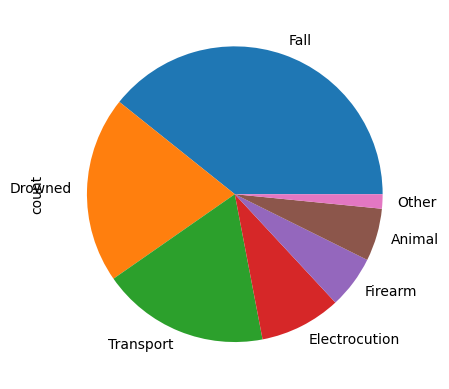

In [91]:
df['Type'].value_counts().plot(kind='pie')
plt.show()

C:\Users\Softlaptop\AppData\Local\Temp\ipykernel_5652\3145964535.py:1: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



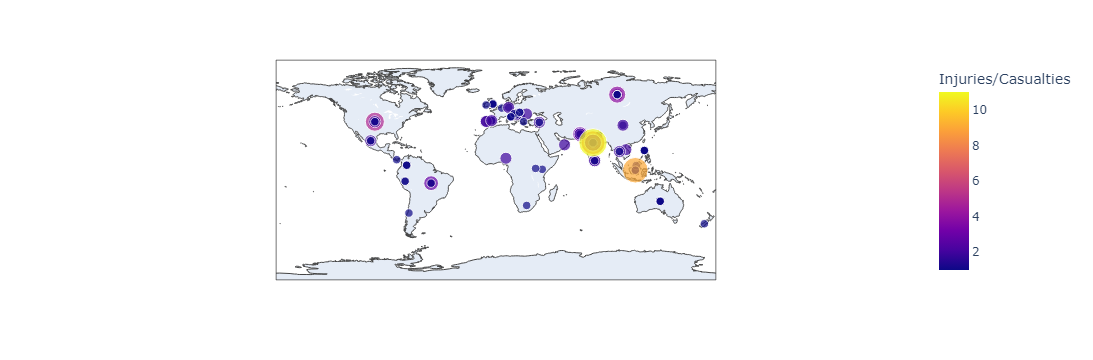

In [103]:
px.scatter_geo(
    df,
    locations='Country',
    locationmode='country names',
    size='Injuries/Casualties',
    color='Injuries/Casualties',
    hover_name='Type'
)



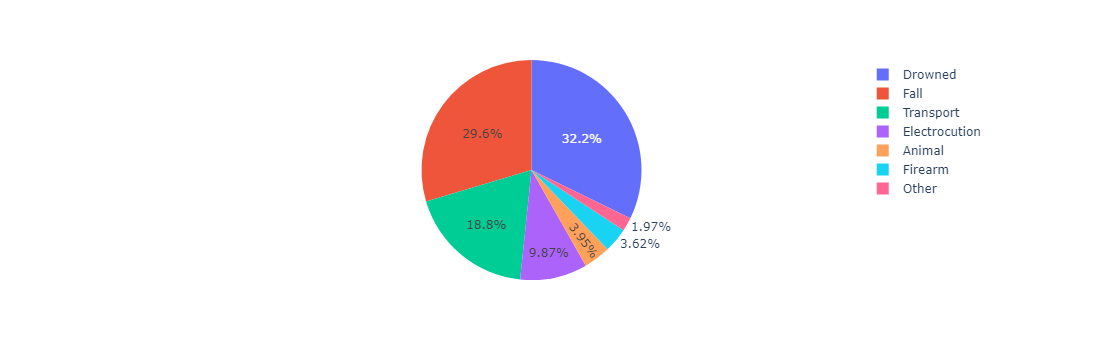

In [107]:
px.pie(df,names='Type',values='Injuries/Casualties')

In [113]:
df2=df.groupby('Type')['Type'].value_counts()

In [116]:
df2=pd.DataFrame(data=df2)

In [124]:
df2.reset_index(inplace=True)

In [125]:
df2

,Type,count
0,Animal,11
1,Drowned,39
2,Electrocution,17
3,Fall,75
4,Firearm,11
5,Other,3
6,Transport,35


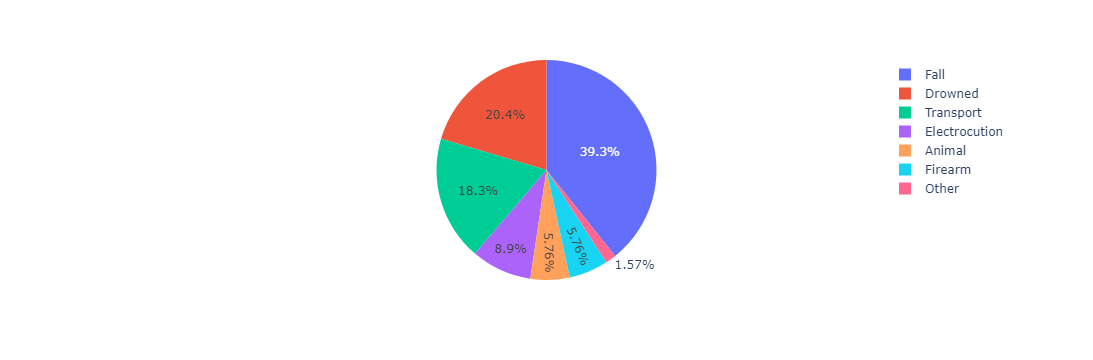

In [126]:
px.pie(df2,names='Type',values='count')